Linear SVM Classification
Classes: Setosa (0), Non-Setosa (1)
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Non-Setosa       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



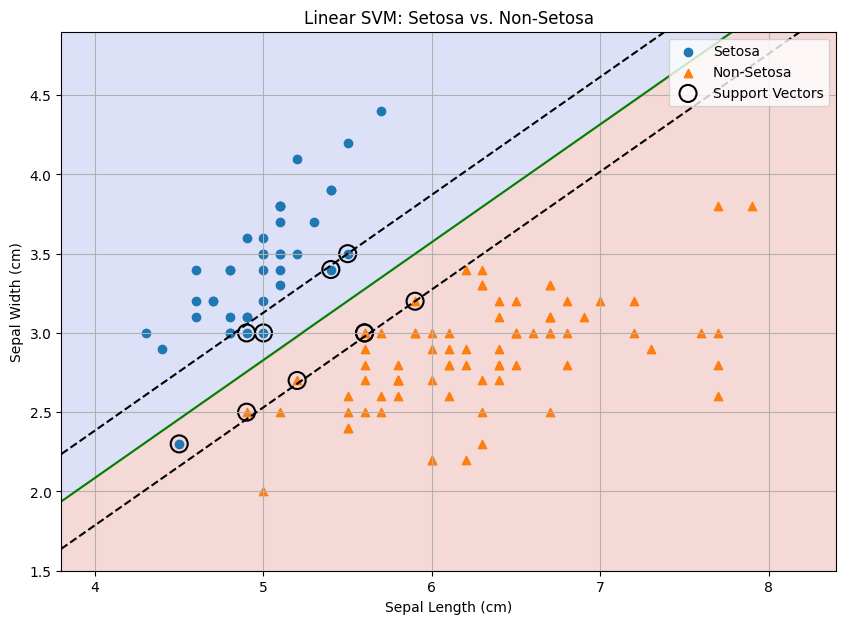

Number of support vectors: 10

Margin Explanation:
The solid green line is the decision boundary.
The dashed black lines represent the margins.
Support vectors are the closest training points to the boundary.
SVM chooses the boundary that maximizes the margin.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data[:, :2]
y = (iris.target != 0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Linear SVM Classification")
print("Classes: Setosa (0), Non-Setosa (1)")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Setosa", "Non-Setosa"]
))

scaler = model.named_steps["standardscaler"]
svm = model.named_steps["svc"]

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid).reshape(xx.shape)

grid_scaled = scaler.transform(grid)
decision_values = svm.decision_function(grid_scaled).reshape(xx.shape)

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    alpha=0.2,
    cmap=plt.cm.coolwarm
)

plt.contour(
    xx, yy, decision_values,
    levels=[-1, 0, 1],
    colors=["black", "green", "black"],
    linestyles=["--", "-", "--"]
)

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label="Setosa",
    marker="o"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Non-Setosa",
    marker="^"
)

support_vectors = scaler.inverse_transform(svm.support_vectors_)

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=150,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Linear SVM: Setosa vs. Non-Setosa")
plt.legend()
plt.grid(True)
plt.show()

print("Number of support vectors:", len(svm.support_vectors_))
print("\nMargin Explanation:")
print("The solid green line is the decision boundary.")
print("The dashed black lines represent the margins.")
print("Support vectors are the closest training points to the boundary.")
print("SVM chooses the boundary that maximizes the margin.")